# PREVISION ET ANALYSE PREDICTIVE.

## I. Comprehension du probleme.

Afin de mieux anticiper ses ventes futures, AFRICA DISTRIBUTION SARL cherche à cibler les produits à forte demande potentielle et à dimensionner précisément ses besoins futurs en stocks.

## II. Objectif principal.

prévoir les ventes futures d'AFRICA DISTRIBUTION SARL sur les trois prochains mois à partir des données historiques, afin d'identifier les produits à forte demande future et d'estimer les besoins futurs en stock.

## III. Importation des donnees.

In [196]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [197]:
dossier_nettoye = "DATA_NETTOYEE"

os.makedirs(dossier_nettoye, exist_ok=True)
fichiers = os.listdir(dossier_nettoye)

print(fichiers)

['.gitkeep', 'achats_nettoye.csv', 'clients_nettoye.csv', 'commerciaux_nettoye.csv', 'depenses_nettoye.csv', 'fournisseurs_nettoye.csv', 'livraisons_nettoye.csv', 'magasins_nettoye.csv', 'produits_nettoye.csv', 'stocks_nettoye.csv', 'ventes_nettoye.csv']


In [198]:
ventes = pd.read_csv(os.path.join(dossier_nettoye, "ventes_nettoye.csv"))
produits = pd.read_csv(os.path.join(dossier_nettoye, "produits_nettoye.csv"))
livraisons = pd.read_csv(os.path.join(dossier_nettoye, "livraisons_nettoye.csv"))
stocks = pd.read_csv(os.path.join(dossier_nettoye, "stocks_nettoye.csv"))

## IV. Exploration des donnees.

Table ventes.

In [199]:
ventes.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_vente             50000 non-null  str    
 1   date_vente           49901 non-null  str    
 2   id_client            50000 non-null  str    
 3   id_produit           50000 non-null  str    
 4   id_magasin           50000 non-null  str    
 5   id_commercial        50000 non-null  str    
 6   quantite             50000 non-null  int64  
 7   prix_unitaire_fcfa   50000 non-null  float64
 8   remise_pct           50000 non-null  float64
 9   cout_unitaire_fcfa   50000 non-null  float64
 10  mode_paiement        50000 non-null  str    
 11  statut_vente         50000 non-null  str    
 12  canal_vente          50000 non-null  str    
 13  chiffre_affaire_net  50000 non-null  float64
 14  cout_total_ligne     50000 non-null  float64
 15  marge_brute_ligne    50000 non-null  float64
 1

Supprimer les dates manquantes car en fesant une prevision des ventes dans le temps , les ventes sans date ne pourons pas etre placer sur une serie temporelle.

Table produits.

In [200]:
produits.info()


<class 'pandas.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_produit             501 non-null    str    
 1   nom_produit            501 non-null    str    
 2   categorie              501 non-null    str    
 3   marque                 501 non-null    str    
 4   cout_achat_unitaire    500 non-null    float64
 5   prix_vente_catalogue   500 non-null    float64
 6   unite                  501 non-null    str    
 7   seuil_alerte           500 non-null    float64
 8   fournisseur_principal  501 non-null    str    
 9   categorie_corrigee     500 non-null    str    
dtypes: float64(3), str(7)
memory usage: 39.3 KB


Garder le produit inconnu qui avait ete ajouter pour conserver la cohérence des totaux globaux. L'exclure uniquement lors des analyses par produit ou du calcul des besoins en stock.

Table stocks.

In [201]:
stocks.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   id_mouvement        20000 non-null  str  
 1   date_mouvement      20000 non-null  str  
 2   id_produit          20000 non-null  str  
 3   id_magasin          20000 non-null  str  
 4   type_mouvement      20000 non-null  str  
 5   quantite            20000 non-null  int64
 6   motif               20000 non-null  str  
 7   reference_document  20000 non-null  str  
dtypes: int64(1), str(7)
memory usage: 1.2 MB


Table livraisons.

In [202]:
livraisons.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_livraison         15000 non-null  str    
 1   date_commande        15000 non-null  str    
 2   date_prevue          15000 non-null  str    
 3   date_livraison       14775 non-null  str    
 4   id_client            15000 non-null  str    
 5   id_magasin           15000 non-null  str    
 6   transporteur         15000 non-null  str    
 7   cout_livraison_fcfa  15000 non-null  float64
 8   statut_livraison     15000 non-null  str    
dtypes: float64(1), str(8)
memory usage: 1.0 MB


Verification de la presence de la date de commande ou de la date prevue sur les ligne dont la date de livraison est absente.

In [203]:
vides_livraison = livraisons[livraisons["date_livraison"].isna()]

# Nombre total de lignes concernées
print("Nombre de date_livraison vides :", len(vides_livraison))

# Vérifier combien ont une date de commande ou une date prévue renseignée
# (remplace 'date_commande' et 'date_prevue' par les vrais noms de tes colonnes)
cols_a_verifier = [
    c for c in ["date_commande", "date_prevue"] if c in livraisons.columns
]
print(vides_livraison[cols_a_verifier].notna().sum())

# Aperçu des premières lignes pour contrôler visuellement
print(vides_livraison[cols_a_verifier].head(10))

Nombre de date_livraison vides : 225
date_commande    225
date_prevue      225
dtype: int64
     date_commande date_prevue
221     2025-05-20  2025-05-21
304     2023-05-18  2023-05-21
360     2023-05-01  2023-05-01
610     2025-06-30  2025-06-30
614     2025-11-06  2025-11-10
773     2025-08-16  2025-08-19
872     2024-02-01  2024-02-03
996     2024-01-08  2024-01-09
1176    2023-12-05  2023-12-08
1195    2025-09-26  2025-09-26


Ne pas supprimer les date_livraison vide car ces lignes contiennent les dates de commande et les date prevues qui peuvent etre utiliser pour un suivi ou un delai prevu.

## V. Nettoyage.

Table ventes.

In [204]:
nb_avant = len(ventes)
ventes = ventes.dropna(subset=["date_vente"]).copy()
nb_supprimees = nb_avant - len(ventes)

print(f"Lignes supprimées (date_vente manquante) : {nb_supprimees}")
print(f"Lignes restantes dans ventes : {len(ventes)}")

ventes.info()

Lignes supprimées (date_vente manquante) : 99
Lignes restantes dans ventes : 49901
<class 'pandas.DataFrame'>
Index: 49901 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_vente             49901 non-null  str    
 1   date_vente           49901 non-null  str    
 2   id_client            49901 non-null  str    
 3   id_produit           49901 non-null  str    
 4   id_magasin           49901 non-null  str    
 5   id_commercial        49901 non-null  str    
 6   quantite             49901 non-null  int64  
 7   prix_unitaire_fcfa   49901 non-null  float64
 8   remise_pct           49901 non-null  float64
 9   cout_unitaire_fcfa   49901 non-null  float64
 10  mode_paiement        49901 non-null  str    
 11  statut_vente         49901 non-null  str    
 12  canal_vente          49901 non-null  str    
 13  chiffre_affaire_net  49901 non-null  float64
 14  cout_total_ligne   

## VI. Préparation des séries temporelles et des indicateurs.

1. Série temporelle mensuelle globale (ventes)

Nombre de mois : 36
Début : 2023-01 | Fin : 2025-12
CA min / max : 50835767.52257943 64168761.06803739


<Axes: title={'center': 'CA mensuel global (36 mois)'}, xlabel='mois'>

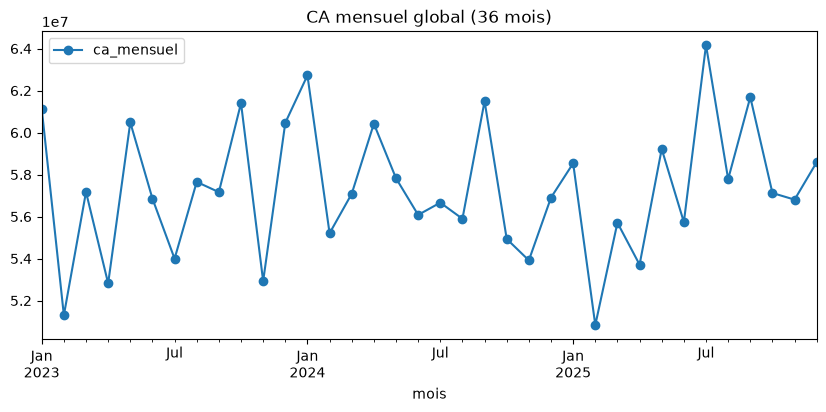

In [205]:
ventes["date_vente"] = pd.to_datetime(ventes["date_vente"])

serie_mensuelle = (
    ventes.assign(mois=ventes["date_vente"].dt.to_period("M"))
    .groupby("mois", as_index=False)
    .agg(
        ca_mensuel=("chiffre_affaire_net", "sum"),
        quantite_mensuelle=("quantite", "sum"),
        marge_mensuelle=("marge_brute_ligne", "sum"),
        nb_ventes=("id_vente", "count"),
    )
    .sort_values("mois")
)

serie_mensuelle["date_mois"] = serie_mensuelle["mois"].dt.to_timestamp()

print("Nombre de mois :", len(serie_mensuelle))


# Aperçu rapide des extrêmes et de la plage couverte
print("Début :", serie_mensuelle["mois"].min(), "| Fin :", serie_mensuelle["mois"].max())
print("CA min / max :", serie_mensuelle["ca_mensuel"].min(), serie_mensuelle["ca_mensuel"].max())

# Courbe d'évolution du CA mensuel
serie_mensuelle.plot(x="mois", y="ca_mensuel", kind="line", marker="o", figsize=(10, 4), title="CA mensuel global (36 mois)")

Impact pour la modélisation : Cette alternance de hausses et de baisses montre qu'une simple moyenne ou tendance linéaire ne suffirait pas : il faut un modèle capable de capter la dynamique temporelle et les variations saisonnières/cycliques pour projeter les 3 prochains mois.

2. Délai moyen réel de livraison (livraisons)

In [206]:
livraisons["date_commande"] = pd.to_datetime(livraisons["date_commande"])
livraisons["date_livraison"] = pd.to_datetime(livraisons["date_livraison"])

livraisons_valides = livraisons.dropna(
    subset=["date_commande", "date_livraison"]
).copy()
livraisons_valides["delai_jours"] = (
    livraisons_valides["date_livraison"] - livraisons_valides["date_commande"]
).dt.days

delai_moyen_jours = livraisons_valides["delai_jours"].mean()
delai_median_jours = livraisons_valides["delai_jours"].median()

print(f"Livraisons valides : {len(livraisons_valides)}")
print(f"Délai moyen réel : {delai_moyen_jours:.2f} jours")
print(f"Délai médian réel : {delai_median_jours:.2f} jours")

Livraisons valides : 14775
Délai moyen réel : 4.17 jours
Délai médian réel : 3.00 jours


Impact pour la modélisation : Pour estimer les besoins en stock, il faut prévoir un délai d'acheminement d'au moins 3 à 4 jours (voire une marge de sécurité) afin d'éviter les ruptures sur les produits à forte demande.

3. Préparation des bases hors PR_INCONNU (demande produit & stocks)

In [207]:
id_inconnu = "PR_INCONNU"

ventes_produits = ventes[ventes["id_produit"] != id_inconnu].copy()
produits_valides = produits[produits["id_produit"] != id_inconnu].copy()
stocks_valides = stocks[stocks["id_produit"] != id_inconnu].copy()

print("Lignes ventes (hors PR_INCONNU) :", len(ventes_produits))
print("Produits valides :", len(produits_valides))
print("Lignes stocks valides :", len(stocks_valides))

Lignes ventes (hors PR_INCONNU) : 49877
Produits valides : 500
Lignes stocks valides : 20000


Impact pour la modélisation : 
.Les 49 877 lignes (soit 24 ventes écartées sur les 49 901 lignes datées) permettent d'entraîner des prévisions de demande produit sans fausser les articles avec des transactions hors catalogue (PR_INCONNU).

.Les 500 produits valides constituent l'ensemble exact des articles pour lesquels il faudra identifier la forte demande future et formuler des recommandations d'approvisionnement.

.Les 20 000 lignes de stocks valides couvrent uniquement ces produits référencés, ce qui permet de comparer directement la demande prévue sur 3 mois au stock disponible et au délai d'acheminement (environ 3 à 4 jours).

## VII. Modélisation et prévision des ventes (3 prochains mois).

. serie_mensuelle représente le jeu d'entraînement et d'évaluation du modèle de prévision.

. mois / date_mois (l'axe du temps).

. ca_mensuel (la variable cible principale).

. quantite_mensuelle, marge_mensuelle, nb_ventes (indicateurs d'accompagnement).

1. Découpage train / test.

In [208]:
# S'assurer que la série est bien triée dans l'ordre chronologique
df_ts = serie_mensuelle.sort_values("date_mois").reset_index(drop=True).copy()

# Découpage chronologique : 30 mois en train, 6 derniers mois en test
n_test = 6
train = df_ts.iloc[:-n_test].copy()
test = df_ts.iloc[-n_test:].copy()

print(
    f"Train : {len(train)} mois ({train['mois'].min()} à {train['mois'].max()})"
)
print(f"Test  : {len(test)} mois ({test['mois'].min()} à {test['mois'].max()})")

Train : 30 mois (2023-01 à 2025-06)
Test  : 6 mois (2025-07 à 2025-12)


Pour un bon équilibre, sur 36 mois (janvier 2023 – décembre 2025), garder les 6 derniers mois (juillet à décembre 2025) pour le test et les 30 premiers mois (janvier 2023 – juin 2025) pour l'entraînement. 

2. Evaluation de different modele.

a. Moyenne mobile.

Moyenne mobile : Pour deviner ce qui va se passer, on fait la moyenne des ventes des derniers mois connus

In [209]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


def evaluer_modele(nom, y_true, y_pred):
  mae = mean_absolute_error(y_true, y_pred)
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
  print(f"{nom:28s} | MAE : {mae:,.0f} | RMSE : {rmse:,.0f} | MAPE : {mape:.2f}%")
  return {"modele": nom, "MAE": mae, "RMSE": rmse, "MAPE": mape}


# Baseline simple : moyenne des 3 derniers mois du train répétée sur les 6 mois de test
pred_mm3 = np.repeat(train["ca_mensuel"].iloc[-3:].mean(), len(test))
res_mm3 = evaluer_modele("Moyenne mobile (3m train)", test["ca_mensuel"].values, pred_mm3)

Moyenne mobile (3m train)    | MAE : 3,138,566 | RMSE : 4,128,055 | MAPE : 5.10%


b. Lissage exponentiel.

In [210]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

modele_hw = ExponentialSmoothing(
    train["ca_mensuel"].reset_index(drop=True),
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=12,
).fit(optimized=True)

pred_hw = modele_hw.forecast(len(test)).values
res_hw = evaluer_modele(
    "Lissage exp. (Holt-Winters)", test["ca_mensuel"].values, pred_hw
)

Lissage exp. (Holt-Winters)  | MAE : 3,592,419 | RMSE : 4,717,710 | MAPE : 5.90%


c. Regression lineaire.

In [211]:
from sklearn.linear_model import LinearRegression

df_reg = df_ts.copy()
df_reg["t"] = np.arange(len(df_reg))
df_reg["mois_num"] = df_reg["date_mois"].dt.month

train_reg = df_reg.iloc[:-n_test].copy()
test_reg = df_reg.iloc[-n_test:].copy()

X_train = pd.concat(
    [
        train_reg[["t"]],
        pd.get_dummies(train_reg["mois_num"], prefix="m", drop_first=True),
    ],
    axis=1,
)
X_test = pd.concat(
    [
        test_reg[["t"]],
        pd.get_dummies(test_reg["mois_num"], prefix="m", drop_first=True),
    ],
    axis=1,
)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

modele_lin = LinearRegression()
modele_lin.fit(X_train, train_reg["ca_mensuel"])
pred_lin = modele_lin.predict(X_test)

res_lin = evaluer_modele(
    "Régression Linéaire (t + mois)", test_reg["ca_mensuel"].values, pred_lin
)

Régression Linéaire (t + mois) | MAE : 2,374,215 | RMSE : 2,843,485 | MAPE : 3.95%


d. SARIMA.

In [212]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

modele_sarima = SARIMAX(
    train["ca_mensuel"].reset_index(drop=True),
    order=(1, 1, 1),
    seasonal_order=(1, 0, 0, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

pred_sarima = modele_sarima.forecast(len(test)).values
res_sarima = evaluer_modele(
    "SARIMA (1,1,1)(1,0,0,12)", test["ca_mensuel"].values, pred_sarima
)

SARIMA (1,1,1)(1,0,0,12)     | MAE : 3,538,915 | RMSE : 4,285,595 | MAPE : 5.80%


In [213]:
import warnings
from prophet import Prophet

warnings.filterwarnings("ignore")

# Préparation des données au format attendu par Prophet ('ds' et 'y')
df_prophet = df_ts[["date_mois", "ca_mensuel"]].rename(
    columns={"date_mois": "ds", "ca_mensuel": "y"}
)

train_p = df_prophet.iloc[:-n_test].copy()
test_p = df_prophet.iloc[-n_test:].copy()

# Création et entraînement du modèle
modele_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
modele_prophet.fit(train_p)

# Prédiction sur l'horizon de test (6 mois)
futur_p = modele_prophet.make_future_dataframe(periods=n_test, freq="MS")
forecast_p = modele_prophet.predict(futur_p)

pred_prophet = forecast_p.iloc[-n_test:]["yhat"].values

res_prophet = evaluer_modele(
    "Prophet", test_p["y"].values, pred_prophet
)

05:03:57 - cmdstanpy - INFO - Chain [1] start processing
05:03:57 - cmdstanpy - INFO - Chain [1] done processing


Prophet                      | MAE : 4,820,436 | RMSE : 5,552,645 | MAPE : 7.99%


3. Modèles de référence (régression linéaire) et prévision sur 3 mois. 

 MAE : 2,374,215 | RMSE : 2,843,485 | MAPE : 3.95%

In [214]:
from sklearn.linear_model import LinearRegression

# 1. Préparation sur l'intégralité des 36 mois
df_full = df_ts.sort_values("date_mois").reset_index(drop=True).copy()
df_full["t"] = np.arange(len(df_full))
df_full["mois_num"] = df_full["date_mois"].dt.month

X_full = pd.concat(
    [
        df_full[["t"]],
        pd.get_dummies(df_full["mois_num"], prefix="m", drop_first=True),
    ],
    axis=1,
)
y_full = df_full["ca_mensuel"]

# 2. Réentraînement du modèle gagnant sur les 36 mois
modele_final = LinearRegression()
modele_final.fit(X_full, y_full)

# 3. Création des 3 mois futurs (2026-01, 2026-02, 2026-03)
n_futur = 3
derniere_date = df_full["date_mois"].iloc[-1]
dates_futures = pd.date_range(
    start=derniere_date + pd.offsets.MonthBegin(1), periods=n_futur, freq="MS"
)

df_futur = pd.DataFrame({
    "date_mois": dates_futures,
    "t": np.arange(len(df_full), len(df_full) + n_futur),
    "mois_num": dates_futures.month,
})

X_futur = pd.concat(
    [
        df_futur[["t"]],
        pd.get_dummies(df_futur["mois_num"], prefix="m", drop_first=True),
    ],
    axis=1,
)
X_futur = X_futur.reindex(columns=X_full.columns, fill_value=0)

# 4. Prévisions sur les 3 prochains mois
df_futur["ca_prevu"] = modele_final.predict(X_futur)

# Affichage 
df_affichage = pd.DataFrame({
    "mois": df_futur["date_mois"].dt.strftime("%Y-%m"),
    "ca_prevu_fcfa": df_futur["ca_prevu"].apply(lambda x: f"{x:,.0f}".replace(",", " ")),
})

print(df_affichage.to_string(index=False))

   mois ca_prevu_fcfa
2026-01    61 343 289
2026-02    52 992 696
2026-03    57 199 961


4. Visualisation (historique + test + projection 3 mois)

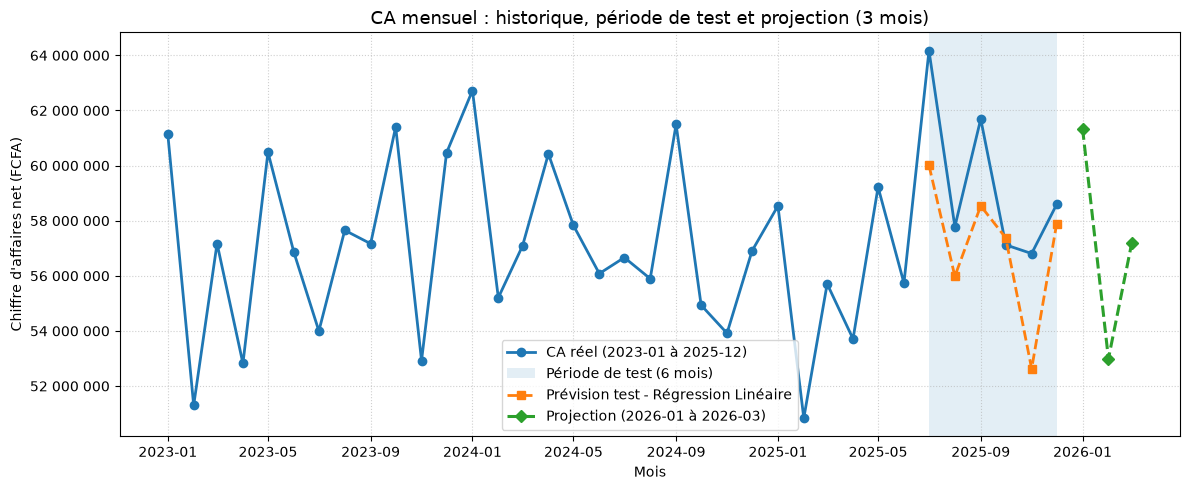

In [215]:
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd

# Préparation des courbes pour le graphique
df_plot = df_ts.sort_values("date_mois").reset_index(drop=True).copy()

# Prédictions du modèle linéaire sur la période de test (pour visualiser l'ajustement)
pred_test_lin = modele_lin.predict(X_test)

# Table des 3 mois futurs
df_fut_plot = df_futur[["date_mois", "ca_prevu"]].copy()

fig, ax = plt.subplots(figsize=(12, 5))

# 1. Historique complet (36 mois : 2023-01 à 2025-12)
ax.plot(
    df_plot["date_mois"],
    df_plot["ca_mensuel"],
    marker="o",
    linewidth=2,
    label="CA réel (2023-01 à 2025-12)",
)

# 2. Mise en évidence de la zone de test (6 derniers mois : 2025-07 à 2025-12)
ax.axvspan(
    test_reg["date_mois"].iloc[0],
    test_reg["date_mois"].iloc[-1],
    alpha=0.12,
    label="Période de test (6 mois)",
)
ax.plot(
    test_reg["date_mois"],
    pred_test_lin,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Prévision test - Régression Linéaire",
)

# 3. Projection sur les 3 prochains mois (2026-01 à 2026-03)
ax.plot(
    df_fut_plot["date_mois"],
    df_fut_plot["ca_prevu"],
    marker="D",
    linestyle="--",
    linewidth=2.2,
    label="Projection (2026-01 à 2026-03)",
)

# Formatage de l'axe Y sans écriture scientifique
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda val, pos: f"{val:,.0f}".replace(",", " "))
)

ax.set_title(
    "CA mensuel : historique, période de test et projection (3 mois)",
    fontsize=13,
)
ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires net (FCFA)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="best")

plt.tight_layout()
plt.show()

La régression linéaire suit fidèlement le cycle saisonnier observé sur l'historique et produit une projection cohérente pour les 3 premiers mois de 2026

## VIII. Analyse de la demande produit et estimation des besoins en stock.

1. Identification des produits suceptible de connaitre une forte demande.

In [216]:
# 1. Exclusion stricte de PR_INCONNU
ventes_prod = ventes[ventes["id_produit"] != "PR_INCONNU"].copy()
produits_valides = produits[produits["id_produit"] != "PR_INCONNU"].copy()

# 2. Agrégation de la demande historique par produit (36 mois : 2023-01 à 2025-12)
nb_mois_hist = df_ts["date_mois"].nunique()

demande_hist = ventes_prod.groupby("id_produit", as_index=False).agg(
    qte_totale=("quantite", "sum"),
    ca_total=("chiffre_affaire_net", "sum"),
    nb_ventes=("id_vente", "count"),
)
demande_hist["demande_mensuelle_moy"] = demande_hist["qte_totale"] / nb_mois_hist
demande_hist["demande_journaliere_moy"] = demande_hist["qte_totale"] / (
    nb_mois_hist * 30
)

# 3. Dynamique récente (6 derniers mois de l'historique : 2025-07 à 2025-12)
derniers_mois = sorted(ventes_prod["annee_mois"].unique())[-6:]
ventes_recentes = ventes_prod[ventes_prod["annee_mois"].isin(derniers_mois)]

demande_recente = ventes_recentes.groupby("id_produit", as_index=False).agg(
    qte_6m_recents=("quantite", "sum")
)
demande_recente["demande_mensuelle_6m"] = demande_recente["qte_6m_recents"] / 6.0

# 4. Fusion avec les informations produits
df_forte_demande = (
    produits_valides[[
        "id_produit",
        "nom_produit",
        "categorie",
        "marque",
        "fournisseur_principal",
    ]]
    .merge(demande_hist, on="id_produit", how="left")
    .merge(demande_recente, on="id_produit", how="left")
    .fillna({
        "qte_totale": 0,
        "ca_total": 0,
        "nb_ventes": 0,
        "demande_mensuelle_moy": 0,
        "demande_journaliere_moy": 0,
        "qte_6m_recents": 0,
        "demande_mensuelle_6m": 0,
    })
)

# Score combinant demande globale et rythme récent (80e percentile = seuil de forte demande)
df_forte_demande["demande_ref_mensuelle"] = np.maximum(
    df_forte_demande["demande_mensuelle_moy"],
    df_forte_demande["demande_mensuelle_6m"],
)
seuil_forte_demande = df_forte_demande["demande_ref_mensuelle"].quantile(0.80)
df_forte_demande["forte_demande"] = (
    df_forte_demande["demande_ref_mensuelle"] >= seuil_forte_demande
)

# Tri des produits les plus demandés
df_forte_demande = df_forte_demande.sort_values(
    "demande_ref_mensuelle", ascending=False
).reset_index(drop=True)

print(
    f"Nombre de produits identifiés à forte demande (top 20 %) :"
    f" {df_forte_demande['forte_demande'].sum()}"
)
print("\nTop 15 produits à forte demande :")
print(
    df_forte_demande[[
        "id_produit",
        "nom_produit",
        "categorie",
        "demande_mensuelle_moy",
        "demande_mensuelle_6m",
        "demande_journaliere_moy",
    ]]
    .head(15)
    .to_string(index=False)
)
# Sauvegarde des 100 produits à forte demande (uniquement nom, catégorie et demande mensuelle 6m)
colonnes_export = ["nom_produit", "categorie", "demande_mensuelle_6m"]

df_top100_forte_demande = df_forte_demande[df_forte_demande["forte_demande"]][
    colonnes_export
].copy()

df_top100_forte_demande.to_excel(
    "produits_forte_demande_100.xlsx",
    index=False,
    sheet_name="Forte_Demande_100",
)

print(
    "\nFichier 'produits_forte_demande_100.xlsx' enregistré avec"
    f" {len(df_top100_forte_demande)} produits."
)

Nombre de produits identifiés à forte demande (top 20 %) : 100

Top 15 produits à forte demande :
id_produit            nom_produit             categorie  demande_mensuelle_moy  demande_mensuelle_6m  demande_journaliere_moy
   PRD0217         Jus Nature 217               Boisson               8.027778             16.666667                 0.267593
   PRD0181            Riz Eco 181 Produits Alimentaires               8.972222             16.333333                 0.299074
   PRD0351         Farine Eco 351              Épicerie               8.444444             15.166667                 0.281481
   PRD0263       Huile Nature 263              Épicerie               7.861111             14.500000                 0.262037
   PRD0284       Biscuit Plus 284 Produits Alimentaires               9.138889             14.500000                 0.304630
   PRD0111           Jus Plus 111               Boisson               8.888889             14.166667                 0.296296
   PRD0143       Caf

Les 100 produits du top 20 % affichent une nette accélération sur les 6 derniers mois par rapport à leur moyenne historique, justifiant une vigilance accrue sur leurs stocks

2. Estimation des besoins futur en stock.

In [217]:
# 1. Stock actuel net par produit (hors PR_INCONNU, quantités déjà signées)
stocks_valides = stocks[stocks["id_produit"] != "PR_INCONNU"].copy()
stock_actuel_df = stocks_valides.groupby("id_produit", as_index=False).agg(
    stock_actuel=("quantite", "sum")
)

# 2. Fusion avec les indicateurs de demande et le seuil d'alerte produit
df_besoins_stock = (
    df_forte_demande.merge(
        produits[["id_produit", "seuil_alerte"]], on="id_produit", how="left"
    )
    .merge(stock_actuel_df, on="id_produit", how="left")
    .fillna({"seuil_alerte": 0, "stock_actuel": 0})
)

# 3. Estimation des besoins futurs (horizon 3 mois = ~90 jours + couverture délai livraison)
horizon_jours = 90
delai_median = 3.0
delai_moyen = 4.17

df_besoins_stock["demande_journaliere_ref"] = (
    df_besoins_stock["demande_ref_mensuelle"] / 30.0
)
df_besoins_stock["besoin_3_mois"] = np.ceil(
    df_besoins_stock["demande_ref_mensuelle"] * 3
)
df_besoins_stock["couverture_delai_moyen"] = np.ceil(
    df_besoins_stock["demande_journaliere_ref"] * delai_moyen
)
df_besoins_stock["besoin_total_estime"] = (
    df_besoins_stock["besoin_3_mois"]
    + df_besoins_stock["couverture_delai_moyen"]
)

# Quantité à commander / réapprovisionner (en tenant compte du stock actuel et du seuil d'alerte)
df_besoins_stock["stock_cible_reappro"] = np.maximum(
    df_besoins_stock["besoin_total_estime"], df_besoins_stock["seuil_alerte"]
)
df_besoins_stock["qte_a_reapprovisionner"] = np.maximum(
    0, df_besoins_stock["stock_cible_reappro"] - df_besoins_stock["stock_actuel"]
)
df_besoins_stock["couverture_actuelle_jours"] = np.where(
    df_besoins_stock["demande_journaliere_ref"] > 0,
    df_besoins_stock["stock_actuel"]
    / df_besoins_stock["demande_journaliere_ref"],
    np.inf,
)

# Priorisation : produits à forte demande avec besoin de réapprovisionnement en tête
df_priorites = df_besoins_stock.sort_values(
    by=["forte_demande", "qte_a_reapprovisionner"], ascending=[False, False]
).reset_index(drop=True)

print(
    "Produits nécessitant un réapprovisionnement immédiat :"
    f" {(df_priorites['qte_a_reapprovisionner'] > 0).sum()}"
)
print(
    "Parmi les 100 produits à forte demande :"
    f" {((df_priorites['forte_demande']) & (df_priorites['qte_a_reapprovisionner'] > 0)).sum()}"
)
print("\nTop 15 besoins de réapprovisionnement (produits à forte demande) :")
print(
    df_priorites[df_priorites["forte_demande"]][[
        "id_produit",
        "nom_produit",
        "stock_actuel",
        "seuil_alerte",
        "besoin_3_mois",
        "qte_a_reapprovisionner",
        "couverture_actuelle_jours",
    ]]
    .head(15)
    .to_string(index=False)
)

Produits nécessitant un réapprovisionnement immédiat : 211
Parmi les 100 produits à forte demande : 46

Top 15 besoins de réapprovisionnement (produits à forte demande) :
id_produit         nom_produit  stock_actuel  seuil_alerte  besoin_3_mois  qte_a_reapprovisionner  couverture_actuelle_jours
   PRD0235    Biscuit Plus 235         -1548          71.0           33.0                  1619.0               -4286.769231
   PRD0402      Jus Nature 402         -1481          57.0           28.0                  1538.0               -4760.357143
   PRD0048     Sucre Nature 48          -999          24.0           33.0                  1034.0               -2724.545455
   PRD0087        Pâtes Eco 87          -864          44.0           29.0                   908.0               -2728.421053
   PRD0152 Biscuit Premium 152          -787          61.0           34.0                   848.0               -2114.328358
   PRD0202      Savon Plus 202          -757          46.0           33.0      

46 des 100 produits à forte demande nécessitent un réapprovisionnement urgent, avec des stocks négatifs qui font gonfler les quantités à commander.

In [218]:
# Filtrage des 211 produits nécessitant un réapprovisionnement
df_211 = df_priorites[df_priorites["qte_a_reapprovisionner"] > 0].copy()

# Colonne explicite pour distinguer les 46 produits à forte demande
df_211["statut_demande"] = np.where(
    df_211["forte_demande"],
    "OUI — Prioritaire ",
    "NON — Demande standard",
)

# Sélection et renommage des colonnes pour l'entreprise / Power BI
export_211 = df_211[[
    "id_produit",
    "nom_produit",
    "categorie",
    "stock_actuel",
    "seuil_alerte",
    "besoin_3_mois",
    "qte_a_reapprovisionner",
    "statut_demande",
]].rename(
    columns={
        "stock_actuel": "stock_actuel_unites",
        "qte_a_reapprovisionner": "quantite_a_commander",
    }
)

print(f"Total produits à réapprovisionner : {len(export_211)}")
print(
    f"Dont forte demande : {(export_211['statut_demande'].str.startswith('OUI')).sum()}"
)

# sauvegarde Excel prêt pour l'équipe achats et Power BI
export_211.to_excel("Liste_211_Produits_Reapprovisionnement.xlsx", index=False)

Total produits à réapprovisionner : 211
Dont forte demande : 46
